# 01 — Casting dataset exploration

**Colab:** Runtime → Change runtime type → **GPU** (optional for this notebook; CPU is fine).

Mount Drive if data lives on Google Drive:
```python
# from google.colab import drive
# drive.mount('/content/drive')
```

In [ ]:
%cd /content

!pip install -q pillow pandas matplotlib scikit-learn pyyaml torch torchvision transformers

!rm -rf /content/casting-defect-vit-resnet
!git clone https://github.com/anshikareddy403/casting-defect-vit-resnet.git

%cd /content/casting-defect-vit-resnet
!ls src/

import os
import sys
from pathlib import Path

ROOT = Path('/content/casting-defect-vit-resnet')
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

print('Setup OK')

/content
Cloning into 'casting-defect-vit-resnet'...
remote: Enumerating objects: 39, done.
remote: Counting objects: 100% (39/39), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 39 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (39/39), 56.81 KiB | 3.55 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/casting-defect-vit-resnet
data.py      __init__.py  __pycache__	   train_vit.py  visualize.py
evaluate.py  metrics.py   train_resnet.py  utils.py
Setup OK


In [ ]:
from google.colab import files
from pathlib import Path

raw = ROOT / 'data' / 'raw'
raw.mkdir(parents=True, exist_ok=True)

print('Choose casting_data.zip from your PC')
files.upload()

!unzip -q -o /content/casting_data.zip -d /content/casting-defect-vit-resnet/data/raw
!ls /content/casting-defect-vit-resnet/data/raw/casting_data/train/

Choose casting_data.zip from your PC


Saving casting_data.zip to casting_data (1).zip
def_front  ok_front


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

from src.data import detect_layout, load_all_samples, resolve_data_root, split_train_val
from src.utils import load_config

cfg = load_config(ROOT / 'configs' / 'default.yaml')
data_root = resolve_data_root(cfg)
print('Data root:', data_root)
print('Detected layout:', detect_layout(data_root))

train_pool, test_samples, layout = load_all_samples(
    data_root, layout=cfg['data'].get('layout', 'auto')
)

try:
    train_samples, val_samples = split_train_val(
        train_pool,
        val_fraction=cfg['data']['val_fraction'],
        seed=cfg['seed'],
        group_augmentations=cfg['data'].get('group_augmentations', True),
    )
except ValueError as e:
    print(f'Warning: Stratified split failed ({e}). Retrying with group_augmentations=False to avoid class membership constraints.')
    train_samples, val_samples = split_train_val(
        train_pool,
        val_fraction=cfg['data']['val_fraction'],
        seed=cfg['seed'],
        group_augmentations=False,
    )

print(f'layout={layout} | train={len(train_samples)} val={len(val_samples)} test={len(test_samples)}')


Data root: /content/casting-defect-vit-resnet/data/raw
Detected layout: kaggle_split
layout=kaggle_split | train=5638 val=995 test=715


In [ ]:
def to_df(samples, split_name):
    return pd.DataFrame({
        'split': split_name,
        'label': ['defective' if s.label else 'acceptable' for s in samples],
        'group_id': [s.group_id for s in samples],
        'path': [str(s.path) for s in samples],
    })

df = pd.concat([
    to_df(train_samples, 'train'),
    to_df(val_samples, 'val'),
    to_df(test_samples, 'test'),
])
df.groupby(['split', 'label']).size().unstack(fill_value=0)

label,acceptable,defective
split,,
test,262,453
train,2444,3194
val,431,564


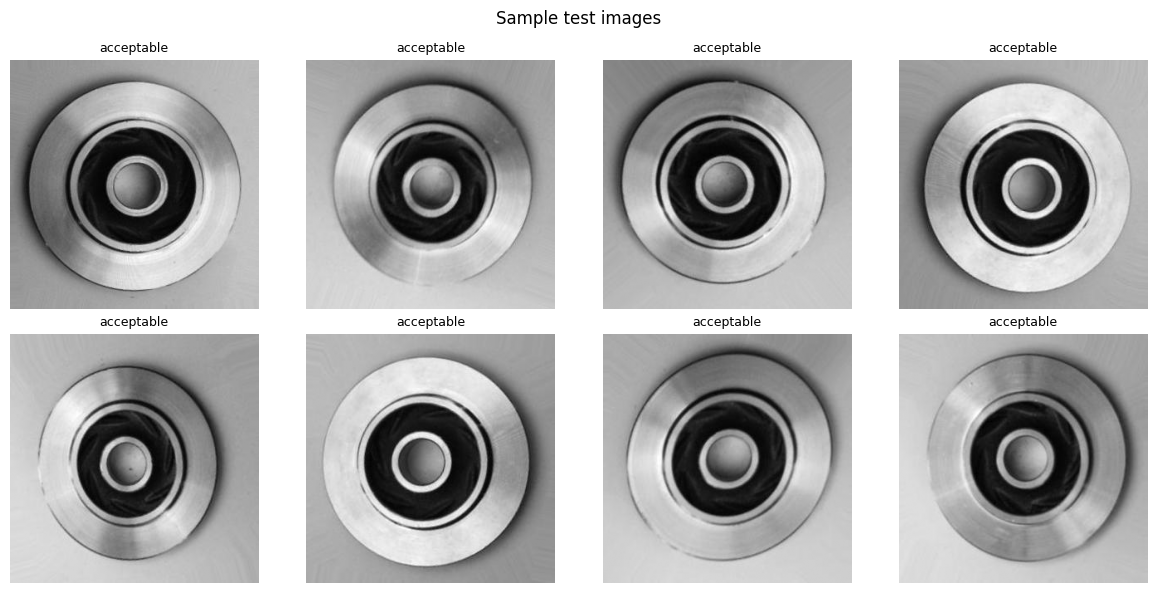

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, sample in zip(axes.flatten(), test_samples[:8]):
    ax.imshow(Image.open(sample.path).convert('L'), cmap='gray')
    ax.set_title('defective' if sample.label else 'acceptable', fontsize=9)
    ax.axis('off')
plt.suptitle('Sample test images')
plt.tight_layout()
plt.show()

## Augmentation grouping sanity check

If using the Kaggle augmented split, verify that filename groups (e.g. `cast_ok_3_1`, `cast_ok_3_2`) never appear in both train and val.

In [ ]:
generic_groups = {'cast_ok_0', 'cast_def_0'}
train_groups = set(s.group_id for s in train_samples if s.group_id not in generic_groups)
val_groups = set(s.group_id for s in val_samples if s.group_id not in generic_groups)
overlap = train_groups & val_groups
print('Overlapping custom augmentation groups between train and val:', len(overlap))
assert len(overlap) == 0, f'Leakage: same augmentation group in train and val: {overlap}'

Overlapping custom augmentation groups between train and val: 0
